<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/Week3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python, NumPy, Pandas & Data Visualization Tutorial

This notebook covers the essential components of modern Python data analysis:
1. **Python Essentials**: Functions, Object-Oriented Programming (OOP), and Comprehensions.
2. **NumPy**: Arrays, Broadcasting, and Vectorized Operations.
3. **Pandas**: DataFrames, Data Cleaning, Merging, and Groupby operations.
4. **Data Visualization**: Matplotlib and Seaborn plotting.

## 1. Python Essentials
Let's start with key Python concepts: custom functions, Object-Oriented Programming (OOP), and comprehensions (list and dictionary).

In [1]:
# --- Functions & Type Hinting ---
def calculate_growth(initial: float, rate: float, periods: int) -> list[float]:
    """Calculates compound growth over multiple periods."""
    history = [initial]
    for _ in range(periods):
        initial += initial * rate
        history.append(round(initial, 2))
    return history

print("Growth History:", calculate_growth(100.0, 0.05, 5))

# --- Object-Oriented Programming (OOP) ---
class DataAsset:
    def __init__(self, name: str, size_mb: float):
        self.name = name
        self.size_mb = size_mb

    def get_info(self) -> str:
        return f"Asset: {self.name} | Size: {self.size_mb} MB"

asset = DataAsset("user_metrics", 245.8)
print(asset.get_info())

# --- List and Dict Comprehensions ---
numbers = [1, 2, 3, 4, 5, 6]
squares_of_evens = [x**2 for x in numbers if x % 2 == 0]
print("Squares of evens:", squares_of_evens)

# Dict comprehension mapping number to its square
square_dict = {x: x**2 for x in numbers}
print("Square Dict:", square_dict)

Growth History: [100.0, 105.0, 110.25, 115.76, 121.55, 127.63]
Asset: user_metrics | Size: 245.8 MB
Squares of evens: [4, 16, 36]
Square Dict: {1: 1, 2: 4, 3: 9, 4: 16, 5: 25, 6: 36}


## 2. NumPy
NumPy introduces fast N-dimensional arrays, vectorized operations, and broadcasting rules.

In [2]:
import numpy as np

# --- Arrays and Vectorized Operations ---
arr = np.array([1, 2, 3, 4, 5])
# Instead of looping, we apply operations to the whole array instantly (vectorization)
print("Array multiplied by 10:", arr * 10)
print("Square root of array elements:", np.sqrt(arr))

# --- Broadcasting ---
# Broadcasting allows arithmetic operations on arrays of different shapes
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_vector = np.array([1, 2, 3])

# Adds row_vector to each row of the matrix automatically
broadcasted_sum = matrix + row_vector
print("\nMatrix:\n", matrix)
print("Row Vector to add:", row_vector)
print("Resulting Matrix after Broadcasting:\n", broadcasted_sum)

Array multiplied by 10: [10 20 30 40 50]
Square root of array elements: [1.         1.41421356 1.73205081 2.         2.23606798]

Matrix:
 [[10 20 30]
 [40 50 60]]
Row Vector to add: [1 2 3]
Resulting Matrix after Broadcasting:
 [[11 22 33]
 [41 52 63]]


## 3. Pandas
Pandas is built on NumPy and offers high-performance DataFrames for data manipulation, cleaning, and analysis.

In [3]:
import pandas as pd

# --- DataFrames Creation & Missing Data Handling ---
data1 = {
    'Employee_ID': [101, 102, 103, 104],
    'Department': ['Engineering', 'Marketing', 'Engineering', 'Sales'],
    'Salary': [95000, 72000, None, 81000]
}

df1 = pd.DataFrame(data1)
print("Original DataFrame with missing values:")
display(df1)

# Cleaning: Fill missing Salary values with the column mean
df1['Salary'] = df1['Salary'].fillna(df1['Salary'].mean())
print("Cleaned DataFrame:")
display(df1)

# --- Merging DataFrames ---
data2 = {
    'Employee_ID': [101, 102, 103, 104],
    'City': ['San Francisco', 'New York', 'Austin', 'Chicago']
}
df2 = pd.DataFrame(data2)

merged_df = pd.merge(df1, df2, on='Employee_ID')
print("Merged DataFrame:")
display(merged_df)

# --- Groupby & Aggregation ---
dept_summary = merged_df.groupby('Department')['Salary'].mean().reset_index()
print("Grouped Average Salary by Department:")
display(dept_summary)

Original DataFrame with missing values:


,Employee_ID,Department,Salary
0,101,Engineering,95000.0
1,102,Marketing,72000.0
2,103,Engineering,NaN
3,104,Sales,81000.0


Cleaned DataFrame:


,Employee_ID,Department,Salary
0,101,Engineering,95000.000000
1,102,Marketing,72000.000000
2,103,Engineering,82666.666667
3,104,Sales,81000.000000


Merged DataFrame:


,Employee_ID,Department,Salary,City
0,101,Engineering,95000.000000,San Francisco
1,102,Marketing,72000.000000,New York
2,103,Engineering,82666.666667,Austin
3,104,Sales,81000.000000,Chicago


Grouped Average Salary by Department:


,Department,Salary
0,Engineering,88833.333333
1,Marketing,72000.000000
2,Sales,81000.000000


## 4. Data Visualization
We use Matplotlib and Seaborn to visualize trends, patterns, and categorical comparisons in our datasets.

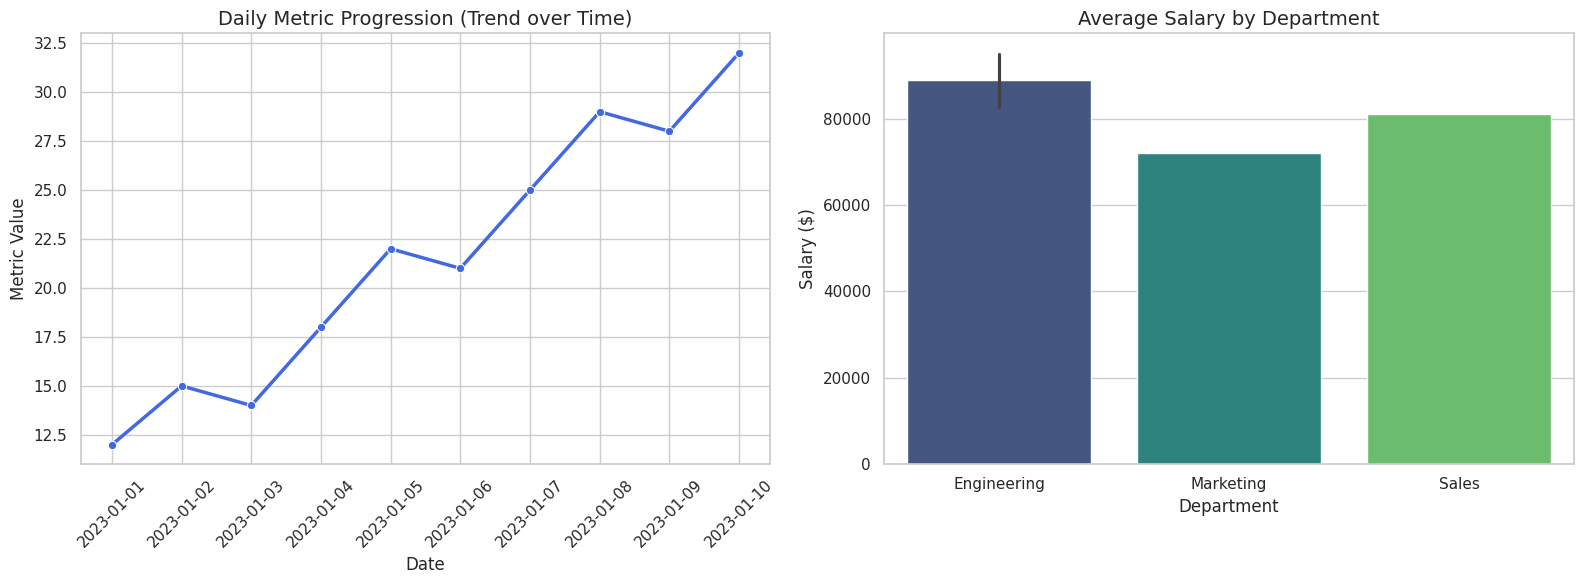

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn aesthetic parameters
sns.set_theme(style="whitegrid")

# Generating synthetic timeline data
temp_dates = pd.date_range(start="2023-01-01", periods=10, freq="D")
temp_values = [12, 15, 14, 18, 22, 21, 25, 29, 28, 32]

# Create a multi-plot layout
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Line Plot (Matplotlib + Seaborn)
sns.lineplot(x=temp_dates, y=temp_values, marker="o", ax=axes[0], color="royalblue", linewidth=2.5)
axes[0].set_title("Daily Metric Progression (Trend over Time)", fontsize=14)
axes[0].set_xlabel("Date", fontsize=12)
axes[0].set_ylabel("Metric Value", fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Bar Plot (Seaborn Category representation)
sns.barplot(data=merged_df, x="Department", y="Salary", ax=axes[1], hue="Department", palette="viridis", legend=False)
axes[1].set_title("Average Salary by Department", fontsize=14)
axes[1].set_xlabel("Department", fontsize=12)
axes[1].set_ylabel("Salary ($)", fontsize=12)

plt.tight_layout()
plt.show()